# CNN

In [1]:
import sys
import json
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "pyproject.toml").is_file())
MODULE_PATH = PROJECT_ROOT / "cnn" / "cnn_genres_classifier.py"
MODEL_PATH = PROJECT_ROOT / "models" / "cnn.json"
CHUNK_SIZE = 128

spec = importlib.util.spec_from_file_location("cnn_genres_classifier", MODULE_PATH)
cnn = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = cnn
spec.loader.exec_module(cnn)

with open(MODEL_PATH, encoding="utf-8") as f:
    results = json.load(f)

model = results["model"]
labels = np.asarray(model["classes"], dtype=object)

paths = sorted((PROJECT_ROOT / results["metadata"]["data_path"]).rglob("*.png"))
df = pd.DataFrame({"path": paths})
df["filename"] = df["path"].map(lambda p: p.stem)
df["label"] = df["path"].map(lambda p: p.parent.name)
id_parts = df["filename"].str.extract(results["config"]["song_id_pattern"])
df["song_id"] = id_parts[0].str.lower() + id_parts[1]

test_df = df[df["song_id"].isin(results["split"]["test_songs"])].reset_index(drop=True)
y_test = test_df["label"]

proba = np.concatenate(
    [
        cnn.predict_proba(
            np.stack([cnn.load_spectrogram_png(p) for p in test_df["path"].iloc[start:start + CHUNK_SIZE]]),
            MODEL_PATH,
        )[1]
        for start in range(0, len(test_df), CHUNK_SIZE)
    ]
)
y_pred = labels[proba.argmax(axis=1)]

print(f"Project root: {PROJECT_ROOT}")
print(f"Holdout fragments: {len(test_df)} | Songs: {test_df['song_id'].nunique()}")
print(f"Holdout accuracy: {(y_pred == y_test).mean():.4f} | Stored: {results['holdout']['accuracy']:.4f}")

Project root: C:\PrograPhil\Jazz-Inador
Holdout fragments: 2000 | Songs: 200
Holdout accuracy: 0.7430 | Stored: 0.7430


## Architecture

In [2]:
input_layer = model["input"]
layers = pd.DataFrame(
    [
        {
            "name": layer["name"],
            "type": layer["type"],
            "role": layer["role"],
            "kernel_size": layer.get("kernel_size"),
            "stride": layer.get("stride"),
            "padding": layer.get("padding"),
            "in": layer.get("in_channels", layer.get("in_features")),
            "out": layer.get("out_channels", layer.get("out_features")),
            "output_shape": tuple(layer["output_shape"]),
            "parameters": layer["parameters"],
        }
        for layer in model["layers"]
    ]
).set_index("name")
layers[["in", "out"]] = layers[["in", "out"]].astype("Int64")

print("Input layer")
display(
    pd.Series(
        {
            "source": input_layer["source"],
            "original_image": f"{input_layer['image_width']}x{input_layer['image_height']} RGB",
            "resized_image": f"{input_layer['width']}x{input_layer['height']} ({input_layer['resample']})",
            "shape (C, H, W)": tuple(input_layer["shape"]),
            "scaling": input_layer["scale"],
            "channel_mean": np.round(input_layer["mean"], 4).tolist(),
            "channel_std": np.round(input_layer["std"], 4).tolist(),
        },
        name="value",
    ).to_frame()
)

print("Hidden layers")
display(layers[layers["role"] == "hidden"].drop(columns="role"))

print("Output layer")
display(layers[layers["role"] == "output"].drop(columns="role"))

print(f"Total trainable parameters: {layers['parameters'].sum():,}")

Input layer


,value
source,data/mel_spectrograms PNG (RGB)
original_image,432x288 RGB
resized_image,216x144 (box)
"shape (C, H, W)","(3, 144, 216)"
scaling,1/255
channel_mean,"[0.1923, 0.069, 0.2045]"
channel_std,"[0.2711, 0.1139, 0.2026]"


Hidden layers


,type,kernel_size,stride,padding,in,out,output_shape,parameters
name,,,,,,,,
conv1,conv2d,"[3, 3]","[1, 1]","[1, 1]",3,16,"(16, 144, 216)",448
batch_norm1,batch_norm2d,None,None,None,<NA>,<NA>,"(16, 144, 216)",32
relu1,relu,None,None,None,<NA>,<NA>,"(16, 144, 216)",0
max_pool1,max_pool2d,"[2, 2]","[2, 2]",None,<NA>,<NA>,"(16, 72, 108)",0
conv2,conv2d,"[3, 3]","[1, 1]","[1, 1]",16,32,"(32, 72, 108)",4640
batch_norm2,batch_norm2d,None,None,None,<NA>,<NA>,"(32, 72, 108)",64
relu2,relu,None,None,None,<NA>,<NA>,"(32, 72, 108)",0
max_pool2,max_pool2d,"[2, 2]","[2, 2]",None,<NA>,<NA>,"(32, 36, 54)",0
conv3,conv2d,"[3, 3]","[1, 1]","[1, 1]",32,64,"(64, 36, 54)",18496


Output layer


,type,kernel_size,stride,padding,in,out,output_shape,parameters
name,,,,,,,,
output,linear,None,None,None,64,10,"(10,)",650
softmax,softmax,None,None,None,<NA>,<NA>,"(10,)",0


Total trainable parameters: 172,362


## Training

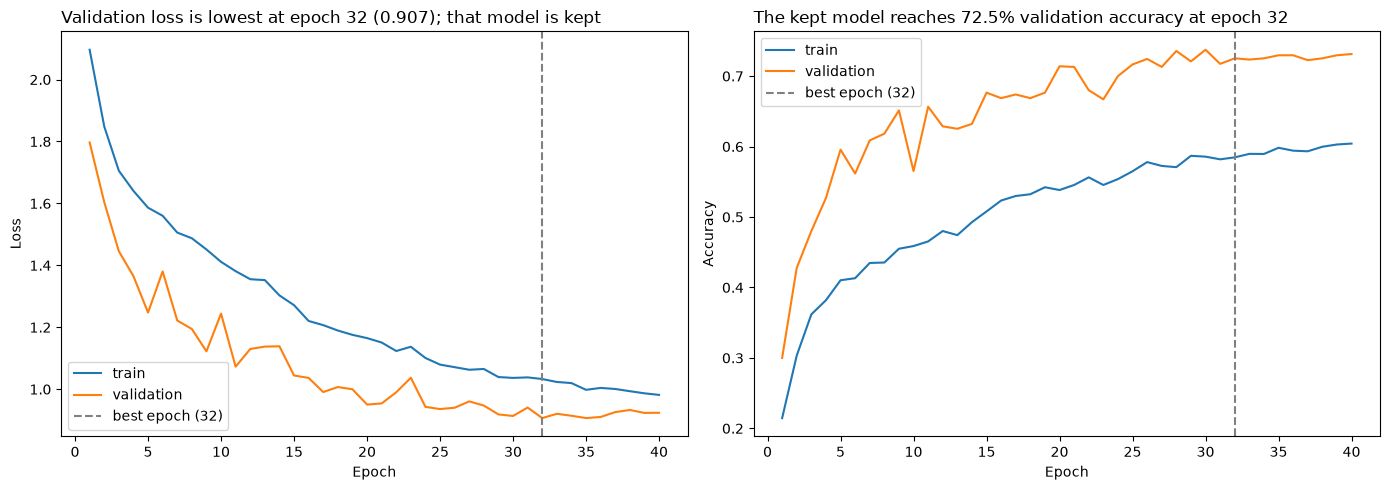

In [3]:
import matplotlib.pyplot as plt

history = pd.DataFrame(results["training"]["history"]).set_index("epoch")
best_epoch = results["training"]["best_epoch"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.index, history[f"train_{metric}"], label="train")
    ax.plot(history.index, history[f"validation_{metric}"], label="validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
    titles = {
        "loss": f"Validation loss is lowest at epoch {best_epoch} ({history.loc[best_epoch, 'validation_loss']:.3f}); that model is kept",
        "accuracy": f"The kept model reaches {history.loc[best_epoch, 'validation_accuracy']:.1%} validation accuracy at epoch {best_epoch}",
    }
    ax.set_title(titles[metric], loc="left")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

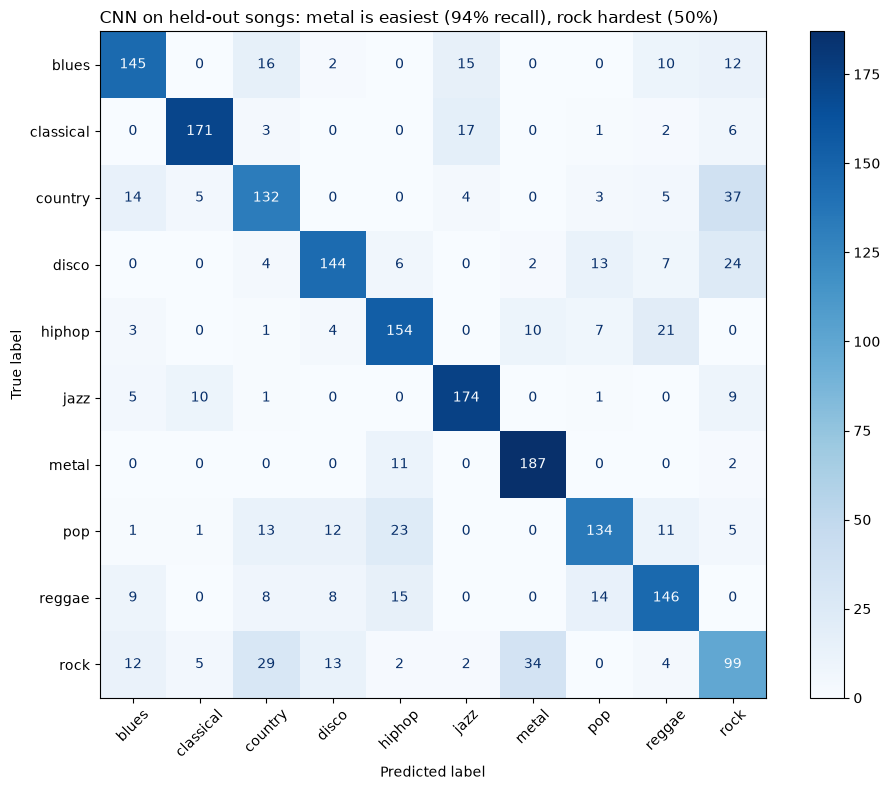

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=True,
)
MODEL_NAME = "CNN"
recalls = cm.diagonal() / cm.sum(axis=1)
ax.set_title(
    f"{MODEL_NAME} on held-out songs: {labels[recalls.argmax()]} is easiest ({recalls.max():.0%} recall), "
    f"{labels[recalls.argmin()]} hardest ({recalls.min():.0%})",
    loc="left",
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.metrics import precision_score, recall_score, accuracy_score

cm = confusion_matrix(y_test, y_pred, labels=labels)
total = cm.sum()
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp
tn = total - tp - fp - fn

metrics = pd.DataFrame(
    {
        "accuracy": (tp + tn) / total,
        "precision": precision_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
        "recall": recall_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
        "support": cm.sum(axis=1),
    },
    index=labels,
)
metrics.index.name = "genre"

display(metrics.round(4))
print(f"Overall accuracy: {accuracy_score(y_test, y_pred):.4f}")

song_proba = pd.DataFrame(proba, columns=labels).groupby(test_df["song_id"]).mean()
song_true = test_df.groupby("song_id")["label"].first().loc[song_proba.index]
print(f"Song-level accuracy (mean of segment probabilities): {(song_proba.idxmax(axis=1) == song_true).mean():.4f}")

,accuracy,precision,recall,support
genre,,,,
blues,0.9505,0.7672,0.725,200
classical,0.9750,0.8906,0.855,200
country,0.9285,0.6377,0.660,200
disco,0.9525,0.7869,0.720,200
hiphop,0.9485,0.7299,0.770,200
jazz,0.9680,0.8208,0.870,200
metal,0.9705,0.8026,0.935,200
pop,0.9475,0.7746,0.670,200
reggae,0.9430,0.7087,0.730,200


Overall accuracy: 0.7430
Song-level accuracy (mean of segment probabilities): 0.8100
